# Prepaid Card Marketing — Mini-Project 2
## Part 2 of 5: Predictor selection and data preparation (Task A, Steps 5–6)

**Purpose.** Turn the cleaned survey data from Part 1 into the fixed inputs that every model in this project will use: one train/test split, one set of 17 predictors, and one preparation pipeline.

| Section | What it delivers |
|---|---|
| 1. Setup | Cleaned data and variable roles loaded from Part 1 |
| 2. Eligible predictors | The pool that selection is allowed to draw from |
| 3. Train/test split | A fixed 80/20 split, made **before** any selection |
| 4. Selecting the predictors | Screening, redundancy control and the final list with reasons |
| 5. Validation | Evidence that the 17 predictors lose nothing against the alternatives |
| 6. Preparation pipeline | Imputation, encoding and standardisation, fitted on training data only |
| 7. Hand-off | Saved files and how the modelling notebook uses them |

### Summary

- **One fixed split:** 5,093 training respondents and 1,274 test respondents, both with an 8.8% usage rate. The split was made before any predictor was chosen, and the test set is not used anywhere in this notebook.
- **17 predictors selected** from 173 eligible variables, covering demographics, banking relationship, liquidity, financial strain, knowledge, well-being and behaviour. Eleven come from a statistical shortlist; six were added for coverage and interpretability. The brief allows up to 20.
- **Age, marital status, sex and SNAP receipt are not eligible as predictors.** They are prohibited bases under fair-lending law (ECOA), so a targeting model should not use them. Age, marital status and SNAP stay in the data files for describing groups.
- **The selection costs nothing in predictive power.** In cross-validation the final 17 score a ROC-AUC of 0.729, as good as the purely statistical alternatives (0.726 and 0.720) and well above using all 173 variables (0.681).
- **The two open decisions turned out not to matter for accuracy.** Adding race/ethnicity moves the ROC-AUC from 0.729 to 0.730, and adding the other non-bank products leaves it at 0.729. Both are far inside the fold-to-fold noise of 0.030, so both are left out.
- **Expect moderate predictive power.** A ROC-AUC near 0.73 means the predictors rank users above non-users clearly better than chance, but far from perfectly. Stronger models in Task B may add a little; they are unlikely to change the picture.
- **One preparation pipeline** (`prep.py`) fills missing values, one-hot encodes two unordered categories and standardises the ordered variables, turning 17 predictors into 26 model columns. It is fitted on training data only.

---
# 1. Setup

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from scipy import stats
from IPython.display import display

from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.pipeline import make_pipeline, Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
import sklearn

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 60, "display.width", 220, "display.max_colwidth", 110, "display.max_rows", 100)

DATA_DIR = Path("data")
FIG_DIR = Path("figures")
TARGET = "PRODUSE_3"
SEED = 42            # one seed for the split and the cross-validation folds, so results are reproducible
TEST_SIZE = 0.20

INK, INK2, MUTED = "#0b0b0b", "#52514e", "#898781"
GRID, AXIS, SURFACE = "#e1e0d9", "#c3c2b7", "#fcfcfb"
BLUE, ORANGE = "#2a78d6", "#eb6834"
SEQ_CMAP = LinearSegmentedColormap.from_list("seq_blue", ["#f3f7fe", "#86b6ef", "#2a78d6", "#104281"])
mpl.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "font.size": 10, "text.color": INK, "axes.labelcolor": INK2,
    "axes.titlesize": 11.5, "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.titlepad": 10,
    "axes.edgecolor": AXIS, "axes.linewidth": 0.8, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.axisbelow": True, "grid.color": GRID, "grid.linewidth": 0.7,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "xtick.labelsize": 9, "ytick.labelsize": 9, "legend.frameon": False, "legend.fontsize": 9,
})


def fmt(df, formats, hide_index=False):
    """Return a display copy of a table with numbers formatted as text."""
    out = df.copy()
    if isinstance(formats, str):
        formats = {c: formats for c in out.columns if pd.api.types.is_numeric_dtype(out[c])}
    for col, pattern in formats.items():
        if col in out.columns:
            out[col] = out[col].map(lambda v, p=pattern: p.format(v) if pd.notna(v) else "")
    return out.reset_index(drop=True) if hide_index else out


clean = pd.read_csv(DATA_DIR / "cfpb_clean.csv", index_col="PUF_ID")
roles = pd.read_csv(DATA_DIR / "variable_roles.csv", index_col="variable")
assert list(clean.columns) == list(roles.index), "Cleaned data and roles table are out of step"

print(f"pandas {pd.__version__} | scikit-learn {sklearn.__version__}")
print(f"Cleaned data: {clean.shape[0]:,} respondents x {clean.shape[1]} columns")
print(f"Prepaid card users: {int(clean[TARGET].sum())} ({clean[TARGET].mean():.2%})")

pandas 3.1.1 | scikit-learn 1.9.1
Cleaned data: 6,367 respondents x 204 columns
Prepaid card users: 560 (8.80%)


---
# 2. Eligible predictors

Part 1 left 178 candidate predictors and two open decisions. Both are settled here, together with a third added after the team's fairness review, and Section 5 measures what the decisions cost.

| Decision | Choice made here | Reason |
|---|---|---|
| Other non-bank products (`PRODUSE_1`, `2`, `4`, `5`) | **Not eligible** | Answered in the same tick-box question as the outcome; a company would not know them for a new prospect |
| Race / ethnicity (`PPETHM`) | **Not eligible as a predictor; kept as a profiling column** | Selecting who receives a financial-product offer by race raises fair-lending concerns. Keeping the column alongside the data still lets the CFPB analysis describe at-risk groups by race and lets the team check the model for disparate outcomes |
| Prohibited bases under fair-lending law: sex (`PPGENDER`), marital status (`PPMARIT`), age (`agecat`), receipt of public assistance (`SNAP`) | **Not eligible as predictors; age, marital status and SNAP kept as describe-only columns** | The Equal Credit Opportunity Act (ECOA) prohibits credit decisions on these bases. A plain prepaid card is not credit, but cards with overdraft features can be, and regulators apply the same thinking to marketing and targeting. The fairness audit in Part 5 found that removing them costs no accuracy |

Each choice can be reversed by editing one line below and re-running the notebook.

In [2]:
INCLUDE_RACE_ETHNICITY = False       # decision 2 above
PROFILE_COLUMNS = ["PPETHM", "sample", "PRODUSE_1", "PRODUSE_2", "PRODUSE_4", "PRODUSE_5"]   # carried along, never used as predictors

candidates = roles.index[roles["role"] == "Candidate predictor"].tolist()
# Prohibited bases under the Equal Credit Opportunity Act (ECOA): sex, marital status, age and receipt of public assistance (SNAP).
# Not eligible as predictors for a targeting model. Age, marital status and SNAP are kept in train/test as describe-only columns.
ECOA_EXCLUDED = ["PPGENDER", "PPMARIT", "agecat", "SNAP"]
DESCRIBE_ONLY = ["agecat", "PPMARIT", "SNAP"]

eligible = [c for c in candidates if (INCLUDE_RACE_ETHNICITY or c != "PPETHM") and c not in ECOA_EXCLUDED]
NOMINAL = set(roles.index[roles["measurement_type"].str.startswith("Nominal")])

print(f"Candidate predictors from Part 1: {len(candidates)}")
print(f"Eligible for selection:           {len(eligible)}")
display(roles.loc[eligible, "measurement_type"].value_counts().rename("eligible predictors").to_frame())

Candidate predictors from Part 1: 178
Eligible for selection:           173


,eligible predictors
measurement_type,
Ordinal (ordered scale or count),83
Binary,77
Nominal (unordered categories),9
Continuous score,4


---
# 3. Train/test split

The data is split **before** any predictor is chosen. If predictors were chosen using all the data and the split made afterwards, the test set would already have influenced the model, and its results would look better than they really are.

- **80% training (used for everything in this notebook), 20% test (set aside, untouched until final model evaluation).**
- **Stratified on the outcome**, so both parts have the same share of prepaid users.
- **Fixed random seed**, so every team member gets the identical split.

In [3]:
train, test = train_test_split(clean, test_size=TEST_SIZE, stratify=clean[TARGET], random_state=SEED)

SAMPLE_LABELS = {1: "General population", 2: "Age 62+ oversample", 3: "Race/ethnicity and poverty oversample"}
balance = pd.DataFrame({
    "Respondents": [len(train), len(test)],
    "Prepaid users": [int(train[TARGET].sum()), int(test[TARGET].sum())],
    "Usage rate": [train[TARGET].mean(), test[TARGET].mean()],
    **{f"Share: {label}": [(train["sample"] == k).mean(), (test["sample"] == k).mean()] for k, label in SAMPLE_LABELS.items()},
    "Mean income band (1-9)": [train["PPINCIMP"].mean(), test["PPINCIMP"].mean()],
    "Mean age band (1-8)": [train["agecat"].mean(), test["agecat"].mean()],
}, index=["Training set", "Test set"])
display(fmt(balance, {"Respondents": "{:,}", "Usage rate": "{:.2%}", "Mean income band (1-9)": "{:.2f}", "Mean age band (1-8)": "{:.2f}",
                      **{c: "{:.1%}" for c in balance.columns if c.startswith("Share")}}).T)
assert set(train.index).isdisjoint(test.index) and len(train) + len(test) == len(clean)

,Training set,Test set
Respondents,"5,093","1,274"
Prepaid users,448,112
Usage rate,8.80%,8.79%
Share: General population,78.5%,77.0%
Share: Age 62+ oversample,15.5%,16.2%
Share: Race/ethnicity and poverty oversample,6.0%,6.8%
Mean income band (1-9),5.53,5.47
Mean age band (1-8),4.46,4.47


**Result.** 5,093 respondents for training and 1,274 for testing. The two parts match on the outcome (8.80% and 8.79% users, 448 and 112 people), on the mix of survey samples, and on average income and age. The test set is now set aside.

---
# 4. Selecting the predictors

**From here on, only the training set is used.**

The brief allows up to 20 predictors. The selection has three steps:

1. **Screen** every eligible variable for the strength of its link to prepaid use.
2. **Remove redundancy**, so that several versions of the same signal do not crowd out other themes.
3. **Apply judgement** for coverage and interpretability, with every change from the statistical shortlist written down.

### 4.1 Screening

Same measure as Part 1 (bias-corrected Cramér's V, 0 = no association, 1 = perfect), recomputed on the training set only.

In [4]:
def levels(series, col):
    """Continuous scores are cut into fifths so that every variable is compared as categories."""
    if roles.loc[col, "measurement_type"] == "Continuous score":
        return pd.qcut(series, 5, labels=False, duplicates="drop")
    return series


def cramers_v(x, y):
    ct = pd.crosstab(x, y)
    chi2, p, _, _ = stats.chi2_contingency(ct, correction=False)
    n = ct.to_numpy().sum()
    r, k = ct.shape
    phi2 = max(0.0, chi2 / n - (k - 1) * (r - 1) / (n - 1))
    r_c, k_c = r - (r - 1) ** 2 / (n - 1), k - (k - 1) ** 2 / (n - 1)
    return np.sqrt(phi2 / max(min(k_c - 1, r_c - 1), 1e-9)), p


rows = []
for col in eligible:
    ok = train[col].notna()
    v, p = cramers_v(levels(train.loc[ok, col], col), train.loc[ok, TARGET])
    rows.append({"variable": col, "cramers_v": v, "p_value": p})
screen = pd.DataFrame(rows).set_index("variable").join(roles[["label", "group", "measurement_type", "pct_missing"]])
screen["significant"] = stats.false_discovery_control(screen["p_value"], method="bh") < 0.05
screen = screen.sort_values("cramers_v", ascending=False)

print(f"Eligible predictors screened on the training set: {len(screen)}")
print(f"Reliably associated with prepaid use (5% false-discovery rate): {int(screen['significant'].sum())}")
display(fmt(screen.head(15)[["label", "group", "cramers_v"]], {"cramers_v": "{:.3f}"}))

Eligible predictors screened on the training set: 173
Reliably associated with prepaid use (5% false-discovery rate): 133


,label,group,cramers_v
variable,,,
SAVINGSRANGES,How much money do you have in savings today...?,"Housing, savings and household resources",0.194
HARDSHIP_COUNT,Number of material hardships experienced sometimes or often (0-6),"Financial strain, hardship and shocks",0.185
MATHARDSHIP_1,Worried whether food would run out before got money to buy more,"Financial strain, hardship and shocks",0.178
MATHARDSHIP_2,Food didn't last and didn't have money to get more,"Financial strain, hardship and shocks",0.170
PPINCIMP,Household Income,Demographics and geography,0.170
fpl,Poverty status,Demographics and geography,0.169
ABSORBSHOCK,"Confidence in ability to raise $2,000 in 30 days","Financial strain, hardship and shocks",0.167
KHscore,Knoll and Houts financial knowledge scale score,Financial knowledge and numeracy (tested),0.161
HOUSING,Which one of the following best describes your housing situation?,"Housing, savings and household resources",0.157


### 4.2 Redundancy control

Taking the 20 highest-ranked variables would give several copies of the same thing (three food-hardship measures, two income measures, four liquidity measures). Instead, variables are taken in rank order and **skipped if they are too closely related to one already chosen**.

"Too closely related" means an association of 0.60 or more with any variable already on the list. Association between two predictors is the rank correlation when both are ordered, and Cramér's V when either is an unordered category.

In [5]:
ordered_cols = [c for c in eligible if c not in NOMINAL]
spearman_abs = train[ordered_cols].corr(method="spearman").abs()


def pair_association(a, b):
    """Strength of the relationship between two predictors, 0 to 1."""
    if a in spearman_abs.index and b in spearman_abs.index:
        return spearman_abs.loc[a, b]
    ok = train[a].notna() & train[b].notna()
    return cramers_v(levels(train.loc[ok, a], a), levels(train.loc[ok, b], b))[0]


REDUNDANCY_LIMIT = 0.60
shortlist, skipped = [], []
for col in screen.index:
    if len(shortlist) == 20:
        break
    clash = next((s for s in shortlist if pair_association(col, s) >= REDUNDANCY_LIMIT), None)
    if clash is None:
        shortlist.append(col)
    else:
        skipped.append({"skipped": col, "label": roles.loc[col, "label"], "too close to": clash,
                        "association": pair_association(col, clash)})

print("Statistical shortlist (rank order):")
display(fmt(screen.loc[shortlist, ["label", "group", "cramers_v"]], {"cramers_v": "{:.3f}"}))
print("Skipped as redundant:")
display(fmt(pd.DataFrame(skipped), {"association": "{:.2f}"}, hide_index=True))

Statistical shortlist (rank order):


,label,group,cramers_v
variable,,,
SAVINGSRANGES,How much money do you have in savings today...?,"Housing, savings and household resources",0.194
HARDSHIP_COUNT,Number of material hardships experienced sometimes or often (0-6),"Financial strain, hardship and shocks",0.185
PPINCIMP,Household Income,Demographics and geography,0.170
KHscore,Knoll and Houts financial knowledge scale score,Financial knowledge and numeracy (tested),0.161
HOUSING,Which one of the following best describes your housing situation?,"Housing, savings and household resources",0.157
ENDSMEET,Difficulty of covering monthly expenses and bills,"Financial strain, hardship and shocks",0.155
FWB2_3,I am behind with my finances,Financial well-being,0.152
COLLECT,Contacted by debt collector in past 12 months,"Financial strain, hardship and shocks",0.150
PRODHAVE_1,Has: Checking or Savings Account at a bank or credit union,Financial products held,0.149


Skipped as redundant:


,skipped,label,too close to,association
0,MATHARDSHIP_1,Worried whether food would run out before got money to buy more,HARDSHIP_COUNT,0.80
1,MATHARDSHIP_2,Food didn't last and didn't have money to get more,HARDSHIP_COUNT,0.76
2,fpl,Poverty status,PPINCIMP,0.71
3,ABSORBSHOCK,"Confidence in ability to raise $2,000 in 30 days",SAVINGSRANGES,0.69
4,FWBscore,Financial well-being scale score,SAVINGSRANGES,0.66
5,LMscore,Lusardi and Mitchell financial knowledge scale score,KHscore,0.61
6,FWB2_1,Giving a gift...would put a strain on my finances for the month,ENDSMEET,0.62


### 4.3 The final 17

The statistical shortlist is a starting point, not the answer. It has three weaknesses for this project:

- **It leaves out the respondent's education, employment and health insurance**, which both the card company (segments it can actually reach) and the CFPB (who is at risk) need.
- **It uses single survey items where a full scale exists** (one "behind with my finances" question in place of the ten-item financial well-being score).
- **It over-samples one theme.** Eight of its twenty slots are financial-strain items, including two single hardship questions alongside the hardship count.

The final list keeps the statistical core and swaps the weakest or most duplicative items for those gaps. It stops at 17 rather than filling all 20 slots: the remaining shortlist items duplicate predictors already chosen, and Section 5 shows the 17 lose nothing against the 20-item shortlist. Every variable's reason is recorded below.

In [6]:
FINAL = {
    # Demographics a marketer can reach and a regulator can describe
    "PPINCIMP":       "Strongest demographic gradient (Part 1, 4.1). Chosen over poverty status (fpl): same signal, finer scale.",
    "PPEDUC":         "Added for coverage. Respondent's own education; chosen over household education (HHEDUC) as it describes the person.",
    "HOUSING":        "On the shortlist. Renters and non-owners use prepaid cards far more than homeowners.",
    "EMPLOY":         "Added for coverage. Highest use among the disabled, unemployed and part-time workers.",
    # Banking relationship
    "PRODHAVE_1":     "On the shortlist. Bank-account status is the most independent strong signal (Part 1, 4.7).",
    "PRODHAVE_4":     "On the shortlist. Retirement account: marks attachment to mainstream long-term finance.",
    "PRODHAVE_3":     "Added. Health insurance: second-largest product gap after the bank account.",
    # Liquidity and resources
    "SAVINGSRANGES":  "On the shortlist; the single strongest variable.",
    "ABSORBSHOCK":    "Added. Could raise $2,000 in 30 days: liquidity under stress. Related to savings (0.69) but far fewer missing answers.",
    "VOLATILITY":     "Added. Month-to-month income volatility: irregular income is a stated use case for prepaid cards.",
    # Strain and shocks
    "HARDSHIP_COUNT": "On the shortlist. One count in place of six separate hardship items.",
    "COLLECT":        "On the shortlist. Contact from a debt collector: marker of credit distress.",
    "REJECTED_1":     "On the shortlist. Turned down for credit: blocked access to mainstream credit.",
    "SHOCKS_COUNT":   "On the shortlist. Number of financial shocks in the past year.",
    # Knowledge, well-being, behaviour
    "KHscore":        "On the shortlist. Tested financial knowledge; central to the CFPB 'unsophisticated user' question.",
    "FWBscore":       "Replaces the single item FWB2_3. The CFPB's own ten-item financial well-being score.",
    "MANAGE1_1":      "On the shortlist. Pays bills on time: the strongest money-management behaviour.",
}
selected = list(FINAL)
assert len(selected) == 17 and set(selected) <= set(eligible)   # the brief allows up to 20

dropped_from_shortlist = [c for c in shortlist if c not in selected]
added_to_shortlist = [c for c in selected if c not in shortlist]
print(f"Kept from the statistical shortlist: {len(set(selected) & set(shortlist))} of 20")
print(f"Added by judgement ({len(added_to_shortlist)}): {', '.join(added_to_shortlist)}")
print(f"Dropped from the shortlist ({len(dropped_from_shortlist)}): {', '.join(dropped_from_shortlist)}")

Kept from the statistical shortlist: 11 of 20
Added by judgement (6): PPEDUC, EMPLOY, PRODHAVE_3, ABSORBSHOCK, VOLATILITY, FWBscore
Dropped from the shortlist (9): ENDSMEET, FWB2_3, MATHARDSHIP_3, CONNECT, HHEDUC, REJECTED_2, ACT1_1, MATHARDSHIP_6, KH2correct


In [7]:
PREPARATION = {"scaled": "Impute median, standardise",
               "binary": "Impute most frequent, keep as 0/1",
               "nominal": "Impute most frequent, one-hot encode"}


def preparation_rule(col):
    if col in NOMINAL:
        return PREPARATION["nominal"]
    return PREPARATION["binary"] if roles.loc[col, "measurement_type"] == "Binary" else PREPARATION["scaled"]


# How realistically a card company could know this about a prospect. This is the team's judgement, not a data fact.
AVAILABILITY = {
    "PPINCIMP": "Yes (stated or modelled income)", "agecat": "Yes", "PPEDUC": "Partly (marketing data)", "HOUSING": "Yes (owner / renter)",
    "EMPLOY": "Partly (application data)", "PPMARIT": "Partly (marketing data)",
    "PRODHAVE_1": "Partly (application or partner data)", "PRODHAVE_4": "Partly (application or partner data)", "PRODHAVE_3": "Partly (application data)",
    "SAVINGSRANGES": "Survey only", "ABSORBSHOCK": "Survey only", "VOLATILITY": "Survey only",
    "HARDSHIP_COUNT": "Survey only", "SNAP": "Survey only", "COLLECT": "Yes (credit bureau)", "REJECTED_1": "Partly (credit bureau)",
    "SHOCKS_COUNT": "Survey only", "KHscore": "Survey only", "FWBscore": "Survey only", "MANAGE1_1": "Partly (credit bureau payment history)",
}

features = pd.DataFrame(index=pd.Index(selected, name="variable"))
features["label"] = roles.loc[selected, "label"]
features["theme"] = roles.loc[selected, "group"]
features["measurement_type"] = roles.loc[selected, "measurement_type"]
features["cramers_v_train"] = screen.loc[selected, "cramers_v"].round(3)
features["screening_rank"] = [screen.index.get_loc(c) + 1 for c in selected]
features["pct_missing_train"] = (train[selected].isna().mean() * 100).round(1)
features["closest_other_predictor"] = [max((o for o in selected if o != c), key=lambda o: pair_association(c, o)) for c in selected]
features["association_with_closest"] = [round(pair_association(c, o), 2) for c, o in zip(selected, features["closest_other_predictor"])]
features["preparation"] = [preparation_rule(c) for c in selected]
features["available_to_card_company"] = pd.Series(AVAILABILITY)
features["why_selected"] = pd.Series(FINAL)

display(features[["label", "theme", "cramers_v_train", "screening_rank", "pct_missing_train", "why_selected"]])
display(features["theme"].value_counts().rename("predictors").to_frame())

,label,theme,cramers_v_train,screening_rank,pct_missing_train,why_selected
variable,,,,,,
PPINCIMP,Household Income,Demographics and geography,0.170,5,0.0,"Strongest demographic gradient (Part 1, 4.1). Chosen over poverty status (fpl): same signal, finer scale."
PPEDUC,Education (Highest Degree Received),Demographics and geography,0.111,30,0.0,Added for coverage. Respondent's own education; chosen over household education (HHEDUC) as it describes t...
HOUSING,Which one of the following best describes your housing situation?,"Housing, savings and household resources",0.157,9,0.3,On the shortlist. Renters and non-owners use prepaid cards far more than homeowners.
EMPLOY,Primary or only employment status,"Employment, retirement and military",0.113,28,1.4,"Added for coverage. Highest use among the disabled, unemployed and part-time workers."
PRODHAVE_1,Has: Checking or Savings Account at a bank or credit union,Financial products held,0.149,13,0.0,"On the shortlist. Bank-account status is the most independent strong signal (Part 1, 4.7)."
PRODHAVE_4,Has: Retirement Account (such as a 401k or IRA),Financial products held,0.149,14,0.0,On the shortlist. Retirement account: marks attachment to mainstream long-term finance.
PRODHAVE_3,Has: Health Insurance,Financial products held,0.110,32,0.0,Added. Health insurance: second-largest product gap after the bank account.
SAVINGSRANGES,How much money do you have in savings today...?,"Housing, savings and household resources",0.194,1,18.2,On the shortlist; the single strongest variable.
ABSORBSHOCK,"Confidence in ability to raise $2,000 in 30 days","Financial strain, hardship and shocks",0.167,7,5.3,"Added. Could raise $2,000 in 30 days: liquidity under stress. Related to savings (0.69) but far fewer miss..."


,predictors
theme,
"Financial strain, hardship and shocks",6
Financial products held,3
Demographics and geography,2
"Housing, savings and household resources",2
"Employment, retirement and military",1
Financial knowledge and numeracy (tested),1
Financial well-being,1
Money management behaviour,1


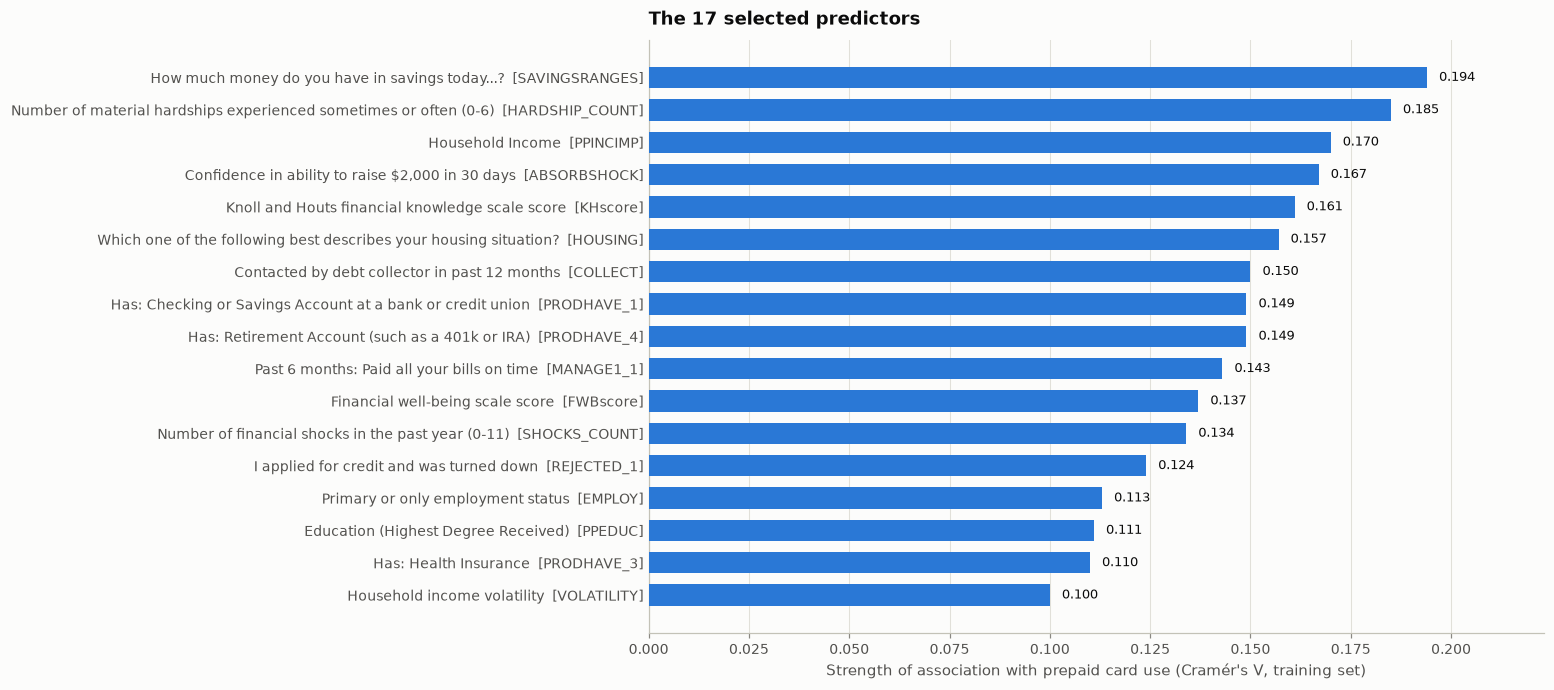

In [8]:
order = features.sort_values("cramers_v_train").index
fig, ax = plt.subplots(figsize=(10.5, 7))
ax.barh(np.arange(len(order)), features.loc[order, "cramers_v_train"], height=0.66, color=BLUE, zorder=3)
for i, col in enumerate(order):
    ax.text(features.loc[col, "cramers_v_train"] + 0.003, i, f"{features.loc[col, 'cramers_v_train']:.3f}", va="center", fontsize=8.5, color=INK)
ax.set_yticks(np.arange(len(order)), [f"{features.loc[c, 'label'][:66]}  [{c}]" for c in order])
ax.set_xlim(0, features["cramers_v_train"].max() * 1.15)
ax.set_xlabel("Strength of association with prepaid card use (Cramér's V, training set)")
ax.set_title(f"The {len(selected)} selected predictors")
ax.grid(axis="y", visible=False)
ax.tick_params(axis="y", length=0)
fig.savefig(FIG_DIR / "12_selected_predictors.png")
plt.show()

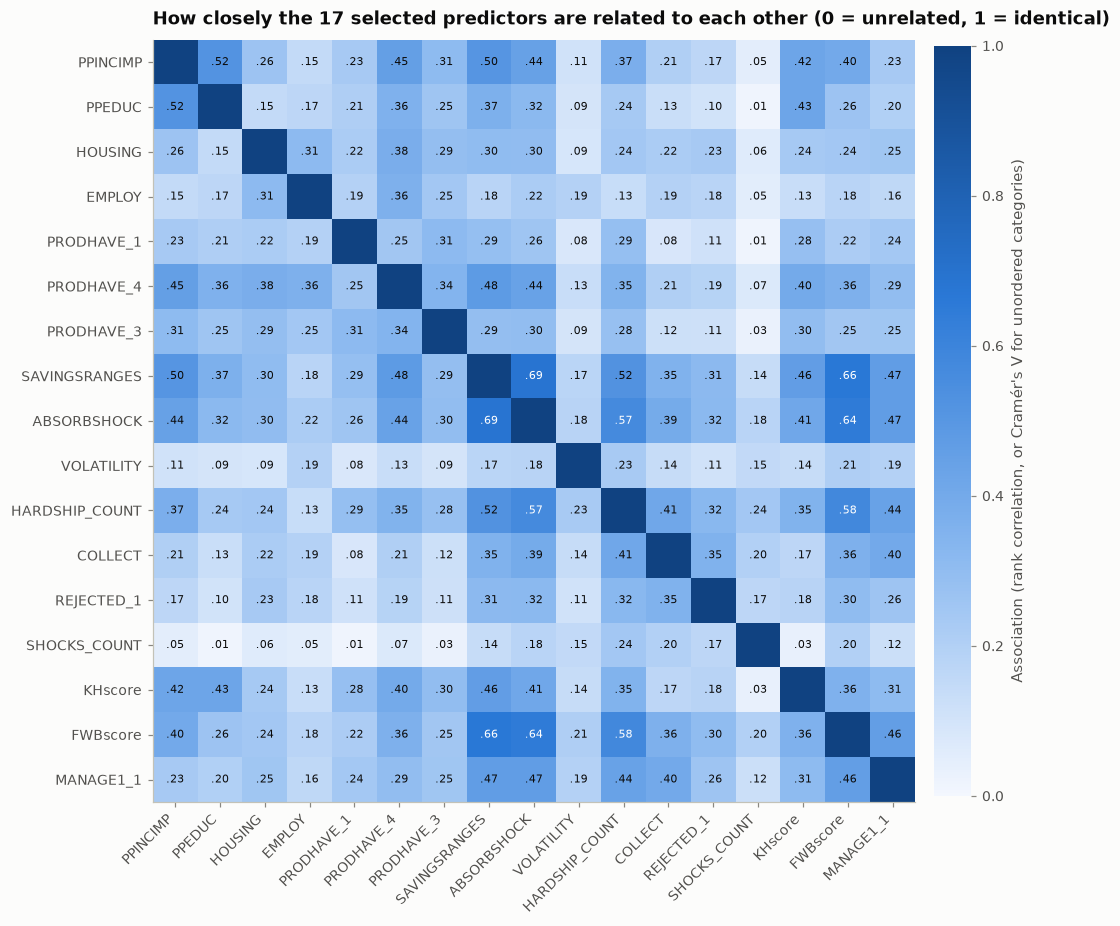

Median association between two selected predictors: 0.25
Pairs at or above the 0.60 redundancy limit: SAVINGSRANGES / ABSORBSHOCK (0.69), SAVINGSRANGES / FWBscore (0.66), ABSORBSHOCK / FWBscore (0.64)


In [9]:
assoc_matrix = pd.DataFrame([[1.0 if a == b else pair_association(a, b) for b in selected] for a in selected],
                            index=selected, columns=selected)
fig, ax = plt.subplots(figsize=(11, 9))
im = ax.imshow(assoc_matrix, cmap=SEQ_CMAP, vmin=0, vmax=1)
ax.set_xticks(range(len(selected)), selected, rotation=45, ha="right")
ax.set_yticks(range(len(selected)), selected)
for i in range(len(selected)):
    for j in range(len(selected)):
        if i != j:
            val = assoc_matrix.iloc[i, j]
            ax.text(j, i, f"{val:.2f}"[1:], ha="center", va="center", fontsize=7.5, color="white" if val > 0.55 else INK)
ax.grid(visible=False)
ax.set_title(f"How closely the {len(selected)} selected predictors are related to each other (0 = unrelated, 1 = identical)")
cbar = fig.colorbar(im, ax=ax, fraction=0.04, pad=0.02)
cbar.set_label("Association (rank correlation, or Cramér's V for unordered categories)")
cbar.outline.set_visible(False)
fig.savefig(FIG_DIR / "13_selected_predictor_overlap.png")
plt.show()

off_diag = assoc_matrix.where(~np.eye(len(selected), dtype=bool))
print(f"Median association between two selected predictors: {np.nanmedian(off_diag.to_numpy()):.2f}")
print(f"Pairs at or above the {REDUNDANCY_LIMIT:.2f} redundancy limit: "
      f"{', '.join(f'{a} / {b} ({assoc_matrix.loc[a, b]:.2f})' for i, a in enumerate(selected) for b in selected[i + 1:] if assoc_matrix.loc[a, b] >= REDUNDANCY_LIMIT)}")

**Takeaways**

- **Eleven of the 17 come straight from the statistical shortlist; six were added by judgement** (education, employment, health insurance, ability to raise \$2,000, income volatility, and the full well-being score).
- **Every major theme is represented:** four demographic and household variables, three banking and product variables, three liquidity variables, four strain variables, and one each for knowledge, well-being and behaviour.
- **The set is mostly non-overlapping.** The typical association between two selected predictors is 0.25.
- **One deliberate exception:** savings, ability to raise \$2,000 and the well-being score are related to each other at 0.64–0.69, above the 0.60 limit used for the shortlist. All three are kept because savings, the strongest variable, is unanswered by 18% of respondents, and the other two carry the same information for those people. When reading model coefficients, treat these three as one "liquidity" group.
- **Section 5 tests whether these judgement calls cost anything.**

---
# 5. Validation: does this set of 17 hold up?

A selection that mixes statistics with judgement should be tested. The check: fit the same simple model (a class-weighted logistic regression) on different sets of predictors and compare how well each ranks users above non-users.

- **Method:** 5-fold cross-validation **within the training set**. The test set is not touched.
- **Metrics:** ROC-AUC (0.5 = coin flip, 1.0 = perfect ranking) and PR-AUC (average precision; the baseline is the 8.8% usage rate). Both are suited to a rare outcome; accuracy is not.
- **This is not the final model.** It is a yardstick for comparing predictor sets. Model choice and tuning are Task B.

In [10]:
def make_preprocessor(cols):
    """Same preparation rules as the shared pipeline in prep.py, for any list of columns."""
    nominal = [c for c in cols if c in NOMINAL]
    binary = [c for c in cols if c not in NOMINAL and roles.loc[c, "measurement_type"] == "Binary"]
    scaled = [c for c in cols if c not in nominal and c not in binary]
    return ColumnTransformer([
        ("scaled", Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())]), scaled),
        ("binary", SimpleImputer(strategy="most_frequent"), binary),
        ("nominal", Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                              ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), nominal),
    ], verbose_feature_names_out=False)


folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)


def cv_score(cols):
    model = make_pipeline(make_preprocessor(cols), LogisticRegression(max_iter=3000, class_weight="balanced"))
    res = cross_validate(model, train[cols], train[TARGET], cv=folds, scoring=["roc_auc", "average_precision"])
    return {"predictors": len(cols), "roc_auc": res["test_roc_auc"].mean(), "roc_auc_sd": res["test_roc_auc"].std(),
            "pr_auc": res["test_average_precision"].mean(), "pr_auc_sd": res["test_average_precision"].std()}


restricted = ["PRODUSE_1", "PRODUSE_2", "PRODUSE_4", "PRODUSE_5"]
predictor_sets = {
    "Final 17 (this notebook)": selected,
    "Statistical shortlist (Section 4.2)": shortlist,
    "Top 17 by screening rank, no redundancy control": screen.index[:17].tolist(),
    f"All {len(eligible)} eligible predictors": eligible,
    "Final 17 + race / ethnicity": selected + ["PPETHM"],
    "Final 17 + other non-bank products": selected + restricted,
}
comparison = pd.DataFrame({name: cv_score(cols) for name, cols in predictor_sets.items()}).T
comparison["predictors"] = comparison["predictors"].astype(int)
display(fmt(comparison, {"roc_auc": "{:.3f}", "roc_auc_sd": "{:.3f}", "pr_auc": "{:.3f}", "pr_auc_sd": "{:.3f}"}))

,predictors,roc_auc,roc_auc_sd,pr_auc,pr_auc_sd
Final 17 (this notebook),17,0.729,0.030,0.224,0.028
Statistical shortlist (Section 4.2),20,0.726,0.024,0.220,0.031
"Top 17 by screening rank, no redundancy control",17,0.720,0.033,0.218,0.038
All 173 eligible predictors,173,0.681,0.023,0.200,0.032
Final 17 + race / ethnicity,18,0.730,0.031,0.231,0.026
Final 17 + other non-bank products,21,0.729,0.029,0.218,0.023


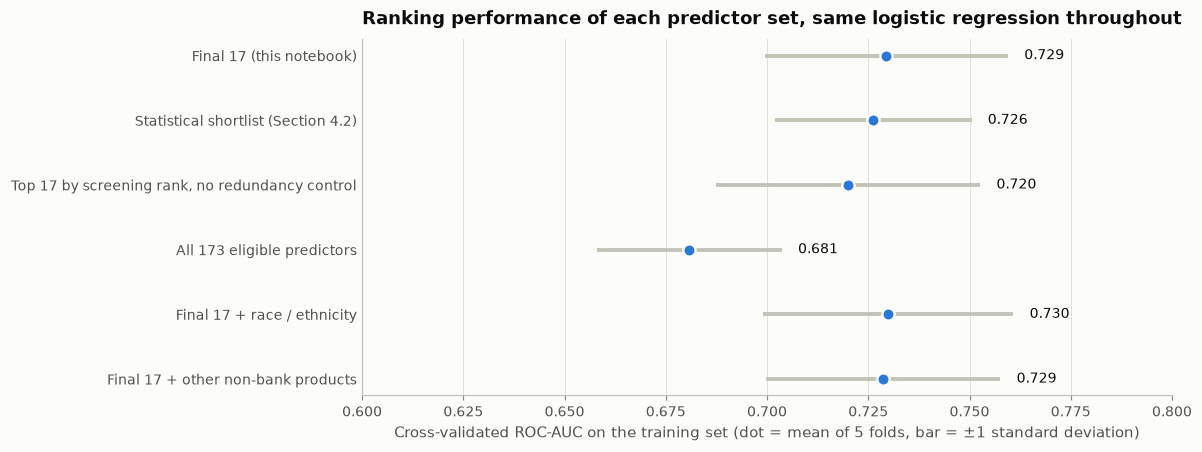

In [11]:
plot = comparison.iloc[::-1]
fig, ax = plt.subplots(figsize=(9.5, 4.2))
y = np.arange(len(plot))
ax.errorbar(plot["roc_auc"], y, xerr=plot["roc_auc_sd"], fmt="o", color=BLUE, ecolor=AXIS, elinewidth=2.5, markersize=8,
            markeredgecolor=SURFACE, markeredgewidth=1.5, zorder=3)
for yi, (m, sd) in enumerate(zip(plot["roc_auc"], plot["roc_auc_sd"])):
    ax.text(m + sd + 0.004, yi, f"{m:.3f}", va="center", fontsize=9, color=INK)
ax.set_yticks(y, plot.index)
ax.set_xlim(0.60, 0.80)
ax.set_xlabel("Cross-validated ROC-AUC on the training set (dot = mean of 5 folds, bar = ±1 standard deviation)")
ax.set_title("Ranking performance of each predictor set, same logistic regression throughout")
ax.grid(axis="y", visible=False)
ax.tick_params(axis="y", length=0)
fig.savefig(FIG_DIR / "14_predictor_set_validation.png")
plt.show()

In [12]:
# What does each predictor contribute on top of the other 19?
base_auc = comparison.loc["Final 17 (this notebook)", "roc_auc"]
drop_one = pd.Series({col: base_auc - cv_score([c for c in selected if c != col])["roc_auc"] for col in selected}, name="auc_lost_if_removed")
contribution = features[["label", "theme"]].join(drop_one).sort_values("auc_lost_if_removed", ascending=False)
display(fmt(contribution, {"auc_lost_if_removed": "{:+.4f}"}))
print(f"Fold-to-fold standard deviation of the ROC-AUC: {comparison.loc['Final 17 (this notebook)', 'roc_auc_sd']:.3f}")
print(f"Largest single-predictor contribution: {drop_one.max():.4f}")

,label,theme,auc_lost_if_removed
variable,,,
SHOCKS_COUNT,Number of financial shocks in the past year (0-11),"Financial strain, hardship and shocks",+0.0091
KHscore,Knoll and Houts financial knowledge scale score,Financial knowledge and numeracy (tested),+0.0057
HOUSING,Which one of the following best describes your housing situation?,"Housing, savings and household resources",+0.0045
PRODHAVE_1,Has: Checking or Savings Account at a bank or credit union,Financial products held,+0.0042
PPINCIMP,Household Income,Demographics and geography,+0.0034
VOLATILITY,Household income volatility,"Financial strain, hardship and shocks",+0.0014
COLLECT,Contacted by debt collector in past 12 months,"Financial strain, hardship and shocks",+0.0009
HARDSHIP_COUNT,Number of material hardships experienced sometimes or often (0-6),"Financial strain, hardship and shocks",+0.0003
MANAGE1_1,Past 6 months: Paid all your bills on time,Money management behaviour,+0.0001


Fold-to-fold standard deviation of the ROC-AUC: 0.030
Largest single-predictor contribution: 0.0091


**Takeaways**

- **The final 17 perform as well as any alternative.** ROC-AUC 0.729, against 0.726 for the 20-item statistical shortlist and 0.720 for the top 17 by rank. These differences are well inside the fold-to-fold variation (0.030), so the three sets are indistinguishable. Choosing for coverage and interpretability cost nothing.
- **More variables is worse, not better.** All 173 eligible predictors score 0.681. With only 448 users in the training set, a model given 173 inputs fits noise.
- **Leaving out race/ethnicity costs nothing measurable** (0.730 with it, 0.729 without). The other predictors already carry that information, which also means the model can still produce different outcomes by race; that should be checked in the CFPB analysis.
- **Leaving out the other non-bank products costs nothing either** (0.729 with them).
- **PR-AUC is 0.224 against a baseline of 0.088**, so the ranking is about 2.5 times better than random at finding users.
- **No single predictor is indispensable.** Removing any one changes the ROC-AUC by less than 0.01. The largest contributions come from the number of financial shocks, financial knowledge, housing and bank-account status. Employment and education add no ranking power on top of the others; they are kept because the card-company and CFPB answers need to describe segments in those terms.
- **Set expectations accordingly.** A ROC-AUC of about 0.73 is moderate. It reflects what Part 1 found: many weak, overlapping signals and no strong one.

---
# 6. Preparation pipeline

Models cannot use the data as it stands: there are missing values, two unordered categories stored as code numbers, and variables on very different scales. The brief also asks for standardisation where necessary.

| Variable type | Predictors | Preparation |
|---|---|---|
| Ordered scales, counts and scores | 10 | Fill missing values with the training median, then standardise to mean 0 and standard deviation 1 |
| Yes/no | 5 | Fill missing values with the most frequent answer; keep as 0/1 |
| Unordered categories | 2 (`HOUSING`, `EMPLOY`) | Fill missing values with the most frequent category, then one-hot encode (one 0/1 column per category) |

**Why standardise.** Logistic regression with a penalty, SVMs and neural networks are sensitive to scale: a 14–95 well-being score would otherwise outweigh a 1–3 scale. Tree-based models (Random Forest, XGBoost, AdaBoost) are unaffected, so one pipeline serves all the models.

**Why this is a pipeline and not a prepared file.** The medians, means and standard deviations must be learned from training data only. The pipeline is therefore saved as code (`prep.py`) and fitted inside each model, including inside every cross-validation fold. A pre-standardised CSV would have used the test rows to compute those numbers.

The pipeline lives in `prep.py` so that every notebook imports exactly the same steps.

In [13]:
features.to_csv(DATA_DIR / "selected_features.csv")

keep = selected + [TARGET] + PROFILE_COLUMNS + DESCRIBE_ONLY
train[keep].to_csv(DATA_DIR / "train.csv")
test[keep].to_csv(DATA_DIR / "test.csv")
print("Saved:", ", ".join(str((DATA_DIR / f).as_posix()) for f in ["selected_features.csv", "train.csv", "test.csv"]))

display(features[["label", "measurement_type", "pct_missing_train", "preparation"]])

Saved: data/selected_features.csv, data/train.csv, data/test.csv


,label,measurement_type,pct_missing_train,preparation
variable,,,,
PPINCIMP,Household Income,Ordinal (ordered scale or count),0.0,"Impute median, standardise"
PPEDUC,Education (Highest Degree Received),Ordinal (ordered scale or count),0.0,"Impute median, standardise"
HOUSING,Which one of the following best describes your housing situation?,Nominal (unordered categories),0.3,"Impute most frequent, one-hot encode"
EMPLOY,Primary or only employment status,Nominal (unordered categories),1.4,"Impute most frequent, one-hot encode"
PRODHAVE_1,Has: Checking or Savings Account at a bank or credit union,Binary,0.0,"Impute most frequent, keep as 0/1"
PRODHAVE_4,Has: Retirement Account (such as a 401k or IRA),Binary,0.0,"Impute most frequent, keep as 0/1"
PRODHAVE_3,Has: Health Insurance,Binary,0.0,"Impute most frequent, keep as 0/1"
SAVINGSRANGES,How much money do you have in savings today...?,Ordinal (ordered scale or count),18.2,"Impute median, standardise"
ABSORBSHOCK,"Confidence in ability to raise $2,000 in 30 days",Ordinal (ordered scale or count),5.3,"Impute median, standardise"


In [14]:
# Load everything back through the shared module, exactly as the modelling notebook will.
import importlib
import prep
importlib.reload(prep)

X_train, X_test, y_train, y_test = prep.load_split()
preprocessor = prep.build_preprocessor()
Xt_train = pd.DataFrame(preprocessor.fit_transform(X_train), index=X_train.index, columns=preprocessor.get_feature_names_out())
Xt_test = pd.DataFrame(preprocessor.transform(X_test), index=X_test.index, columns=preprocessor.get_feature_names_out())   # transform only: nothing is learned from the test set

scaled_cols, binary_cols, nominal_cols = prep.feature_lists()
print(f"Predictors in: {X_train.shape[1]}  ->  model columns out: {Xt_train.shape[1]} "
      f"({len(scaled_cols)} standardised, {len(binary_cols)} yes/no, {Xt_train.shape[1] - len(scaled_cols) - len(binary_cols)} one-hot from {len(nominal_cols)} categories)")
print(f"Training matrix: {Xt_train.shape} | Test matrix: {Xt_test.shape}")

pipeline_checks = {
    "Split reloaded from disk matches the split made in Section 3": bool(X_train.index.equals(train.index) and X_test.index.equals(test.index)),
    "Exactly the 17 selected predictors are loaded": list(X_train.columns) == selected,
    "No missing values remain after preparation (train and test)": bool(Xt_train.notna().all().all() and Xt_test.notna().all().all()),
    "Standardised columns have mean 0 on the training set": bool(np.allclose(Xt_train[scaled_cols].mean(), 0, atol=1e-9)),
    "Standardised columns have standard deviation 1 on the training set": bool(np.allclose(Xt_train[scaled_cols].std(ddof=0), 1, atol=1e-9)),
    "Yes/no columns contain only 0 and 1": bool(Xt_train[binary_cols].isin([0, 1]).all().all()),
    "Each one-hot group sums to exactly 1 per respondent": all(
        bool((Xt_train[[c for c in Xt_train.columns if c.startswith(n + "_")]].sum(axis=1) == 1).all()) for n in nominal_cols),
    "Outcome rate is the same in train and test (to 0.1 point)": abs(y_train.mean() - y_test.mean()) < 0.001,
    "No profiling column or outcome is among the predictors": not (set(prep.PROFILE_COLUMNS) | {TARGET}) & set(X_train.columns),
}
display(pd.DataFrame({"Check": list(pipeline_checks), "Result": ["PASS" if ok else "FAIL" for ok in pipeline_checks.values()]}))
assert all(pipeline_checks.values())

Predictors in: 17  ->  model columns out: 26 (10 standardised, 5 yes/no, 11 one-hot from 2 categories)
Training matrix: (5093, 26) | Test matrix: (1274, 26)


,Check,Result
0,Split reloaded from disk matches the split made in Section 3,PASS
1,Exactly the 17 selected predictors are loaded,PASS
2,No missing values remain after preparation (train and test),PASS
3,Standardised columns have mean 0 on the training set,PASS
4,Standardised columns have standard deviation 1 on the training set,PASS
5,Yes/no columns contain only 0 and 1,PASS
6,Each one-hot group sums to exactly 1 per respondent,PASS
7,Outcome rate is the same in train and test (to 0.1 point),PASS
8,No profiling column or outcome is among the predictors,PASS


In [15]:
print("Model columns after preparation:")
display(pd.DataFrame({"model column": Xt_train.columns,
                      "meaning": prep.readable_names(preprocessor),
                      "train mean": Xt_train.mean().round(3).to_numpy(),
                      "train sd": Xt_train.std(ddof=0).round(3).to_numpy(),
                      "test mean": Xt_test.mean().round(3).to_numpy()}))
drift = (Xt_test[scaled_cols].mean()).abs().max()
print(f"Largest gap between test and training means on a standardised column: {drift:.2f} standard deviations")

Model columns after preparation:


,model column,meaning,train mean,train sd,test mean
0,PPINCIMP,Household Income,-0.000,1.000,-0.021
1,PPEDUC,Education (Highest Degree Received),0.000,1.000,0.005
2,SAVINGSRANGES,How much money do you have in savings today...?,0.000,1.000,0.002
3,ABSORBSHOCK,"Confidence in ability to raise $2,000 in 30 days",-0.000,1.000,0.010
4,VOLATILITY,Household income volatility,0.000,1.000,-0.034
5,HARDSHIP_COUNT,Number of material hardships experienced sometimes or often (0-6),-0.000,1.000,0.009
6,SHOCKS_COUNT,Number of financial shocks in the past year (0-11),-0.000,1.000,0.013
7,KHscore,Knoll and Houts financial knowledge scale score,-0.000,1.000,-0.004
8,FWBscore,Financial well-being scale score,0.000,1.000,-0.033
9,MANAGE1_1,Past 6 months: Paid all your bills on time,-0.000,1.000,0.038


Largest gap between test and training means on a standardised column: 0.04 standard deviations


**Result.** The pipeline turns the 17 predictors into 26 model columns (10 standardised, 5 yes/no, 11 one-hot) with no missing values. All nine checks pass. Test-set means sit within 0.04 standard deviations of the training means on every standardised column, which confirms the two parts are alike and that the test set was only transformed, never used to fit.

---
# 7. Hand-off

### Files produced

| File | Contents |
|---|---|
| `data/train.csv` | 5,093 training respondents: 17 predictors, the outcome, 6 profiling columns, and 3 describe-only columns (age, marital status, SNAP) |
| `data/test.csv` | 1,274 test respondents, same columns. **Do not use until final evaluation** |
| `data/selected_features.csv` | The 17 predictors: label, theme, preparation rule, and reason for selection |
| `prep.py` | `load_split()`, `build_preprocessor()`, `load_profile()`, `readable_names()` |
| `figures/12–14` | Charts from this notebook |

### How Task B (models) starts

```python
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from prep import load_split, build_preprocessor

X_train, X_test, y_train, y_test = load_split()
model = make_pipeline(build_preprocessor(), LogisticRegression(max_iter=3000, class_weight="balanced"))
model.fit(X_train, y_train)
```

### Rules for everyone downstream

1. **Use `load_split()`.** Do not re-split or re-clean the data.
2. **Keep the preprocessor inside the model pipeline**, so it is re-fitted in every cross-validation fold.
3. **Tune on the training set by cross-validation. Touch the test set once, at the end**, to report the final numbers.
4. **Handle the 1-to-10 class imbalance** (class weights or equivalent) and report recall, precision, PR-AUC, ROC-AUC and lift. Accuracy alone is misleading.
5. **Profiling columns are for describing groups, never for predicting.** `load_profile()` returns race/ethnicity, sample type and the other non-bank products for the card-company and CFPB analyses. Age (`agecat`), marital status (`PPMARIT`) and SNAP are also in `train.csv` and `test.csv` for the same purpose only.
6. For any other survey variable, join `data/cfpb_clean.csv` to the split on `PUF_ID`.

### Notes for the next tasks

- **Task B (models):** the logistic regression in Section 5 is a yardstick, not the final model. It gives a floor to beat: cross-validated ROC-AUC 0.729 and PR-AUC 0.224.
- **Task C (card company):** `data/selected_features.csv` has a column, `available_to_card_company`, marking which predictors a company could realistically know about a prospect and which exist only in a survey. It is the team's judgement and should be reviewed, but it matters: a targeting strategy can only use what is observable.
- **Task D (CFPB):** race/ethnicity is not in the model but is available through `load_profile()` for describing at-risk groups and for checking whether the model's scores differ by group.